# Notebook 01: Walmart Store Sales Dataset Overview
**Project:** Walmart Store Sales Forecasting & Business Intelligence System  
**Phase:** Phase 2 — Exploratory Data Analysis & Time-Series Analysis  
**Author:** Lead Data Scientist & Machine Learning Engineer  
**Dataset:** Historical Walmart Sales Data (Kaggle)

---
### Objectives
1. Inspect dimensions, column schemas, and data types across raw and analytical tables.
2. Mathematically audit missing-value proportions and duplicate occurrences.
3. Validate temporal bounds, frequency contiguity, and panel balance (complete vs incomplete series).
4. Profile initial sales distribution and negative value occurrences.


In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(os.path.abspath(".."))
from src.data_loader import load_raw_data, load_processed_data

plt.rcParams['figure.figsize'] = (12, 5)
sns.set_theme(style="whitegrid", palette="muted")
print("Environment initialized successfully.")


Environment initialized successfully.


## 1. Load Processed Analytical Datasets

In [2]:
train, test = load_processed_data()
stores, features, raw_train, raw_test = load_raw_data()

print(f"Train merged shape: {train.shape[0]:,} rows x {train.shape[1]} columns")
print(f"Test merged shape:  {test.shape[0]:,} rows x {test.shape[1]} columns")
print(f"Stores shape:       {stores.shape[0]:,} rows x {stores.shape[1]} columns")
print(f"Features shape:     {features.shape[0]:,} rows x {features.shape[1]} columns")


2026-11-22 15:09:59,305 [INFO] Loading processed datasets from Parquet: E:\MCA projects\Demand-Forecasting\walmart-recruiting-store-sales-forecasting\data\processed


2026-11-22 15:09:59,515 [INFO] Ingesting raw datasets from: E:\MCA projects\Demand-Forecasting\walmart-recruiting-store-sales-forecasting


2026-11-22 15:10:00,105 [INFO] Loaded stores.csv: 45 rows x 3 cols


2026-11-22 15:10:00,106 [INFO] Loaded features.csv.zip: 8190 rows x 12 cols


2026-11-22 15:10:00,108 [INFO] Loaded train.csv.zip: 421570 rows x 5 cols


2026-11-22 15:10:00,110 [INFO] Loaded test.csv.zip: 115064 rows x 4 cols


2026-11-22 15:10:00,302 [INFO] Schema, data types, dates, and ID ranges validated successfully.


Train merged shape: 421,570 rows x 16 columns
Test merged shape:  115,064 rows x 15 columns
Stores shape:       45 rows x 3 columns
Features shape:     8,190 rows x 12 columns


## 2. Dataset Schemas and Data Types

In [3]:
schema_df = pd.DataFrame({
    "Column": train.columns,
    "Dtype": [str(t) for t in train.dtypes.values],
    "Non_Null_Count": train.notnull().sum().values,
    "Missing_Pct": (train.isnull().mean() * 100).round(2).values,
    "Unique_Values": [train[c].nunique() for c in train.columns]
})
schema_df


,Column,Dtype,Non_Null_Count,Missing_Pct,Unique_Values
0,Store,int64,421570,0.00,45
1,Dept,int64,421570,0.00,81
2,Date,datetime64[ns],421570,0.00,143
3,Weekly_Sales,float64,421570,0.00,359464
4,IsHoliday,bool,421570,0.00,2
5,Type,object,421570,0.00,3
6,Size,int64,421570,0.00,40
7,Temperature,float64,421570,0.00,3528
8,Fuel_Price,float64,421570,0.00,892
9,MarkDown1,float64,150681,64.26,2277


## 3. Date Ranges & Sampling Frequency

In [4]:
print(f"Train Date Range: {train['Date'].min().strftime('%Y-%m-%d')} to {train['Date'].max().strftime('%Y-%m-%d')} ({train['Date'].nunique()} weeks)")
print(f"Test Date Range:  {test['Date'].min().strftime('%Y-%m-%d')} to {test['Date'].max().strftime('%Y-%m-%d')} ({test['Date'].nunique()} weeks)")
print(f"Features Date Range: {features['Date'].min().strftime('%Y-%m-%d')} to {features['Date'].max().strftime('%Y-%m-%d')} ({features['Date'].nunique()} weeks)")

# Verify weekly day-of-week consistency
train_dow = train['Date'].dt.day_name().value_counts().to_dict()
test_dow = test['Date'].dt.day_name().value_counts().to_dict()
print(f"Train Day of Week Distribution: {train_dow}")
print(f"Test Day of Week Distribution:  {test_dow}")


Train Date Range: 2010-02-05 to 2012-10-26 (143 weeks)
Test Date Range:  2012-11-02 to 2013-07-26 (39 weeks)
Features Date Range: 2010-02-05 to 2013-07-26 (182 weeks)


Train Day of Week Distribution: {'Friday': 421570}
Test Day of Week Distribution:  {'Friday': 115064}


## 4. Store and Department Entities

In [5]:
n_stores = train['Store'].nunique()
n_depts = train['Dept'].nunique()
unique_sd_train = train.groupby(['Store', 'Dept']).ngroups
unique_sd_test = test.groupby(['Store', 'Dept']).ngroups

print(f"Number of Unique Stores:      {n_stores}")
print(f"Number of Unique Departments: {n_depts}")
print(f"Active (Store, Dept) series in Train: {unique_sd_train:,}")
print(f"Active (Store, Dept) series in Test:  {unique_sd_test:,}")


Number of Unique Stores:      45
Number of Unique Departments: 81
Active (Store, Dept) series in Train: 3,331
Active (Store, Dept) series in Test:  3,169


## 5. Panel Balance: Complete vs Incomplete Time Series

In [6]:
sd_lengths = train.groupby(['Store', 'Dept'])['Date'].nunique()
complete_series = (sd_lengths == 143).sum()
incomplete_series = (sd_lengths < 143).sum()

print(f"Complete Series (all 143 weeks): {complete_series:,} ({complete_series/len(sd_lengths)*100:.2f}%)")
print(f"Incomplete Series (< 143 weeks): {incomplete_series:,} ({incomplete_series/len(sd_lengths)*100:.2f}%)")
print(f"Min weeks observed: {sd_lengths.min()} | Median: {sd_lengths.median():.0f} | Max: {sd_lengths.max()}")


Complete Series (all 143 weeks): 2,660 (79.86%)
Incomplete Series (< 143 weeks): 671 (20.14%)


Min weeks observed: 1 | Median: 143 | Max: 143


## 6. Initial Sales and Negative Records Profile

In [7]:
sales = train['Weekly_Sales']
neg_sales = train[train['Weekly_Sales'] < 0]

print("=== Weekly Sales Summary Statistics ===")
print(sales.describe())
print(f"Skewness: {sales.skew():.3f} | Kurtosis: {sales.kurtosis():.3f}")
print(f"Negative Sales Records: {len(neg_sales):,} ({len(neg_sales)/len(train)*100:.4f}%)")
print(f"Negative Sales Dollar Sum: ${neg_sales['Weekly_Sales'].sum():,.2f}")


=== Weekly Sales Summary Statistics ===
count    421570.000000
mean      15981.258123
std       22711.183519
min       -4988.940000
25%        2079.650000
50%        7612.030000
75%       20205.852500
max      693099.360000
Name: Weekly_Sales, dtype: float64
Skewness: 3.262 | Kurtosis: 21.491
Negative Sales Records: 1,285 (0.3048%)
Negative Sales Dollar Sum: $-88,161.56


## 7. Master Timeline Overview Visualization

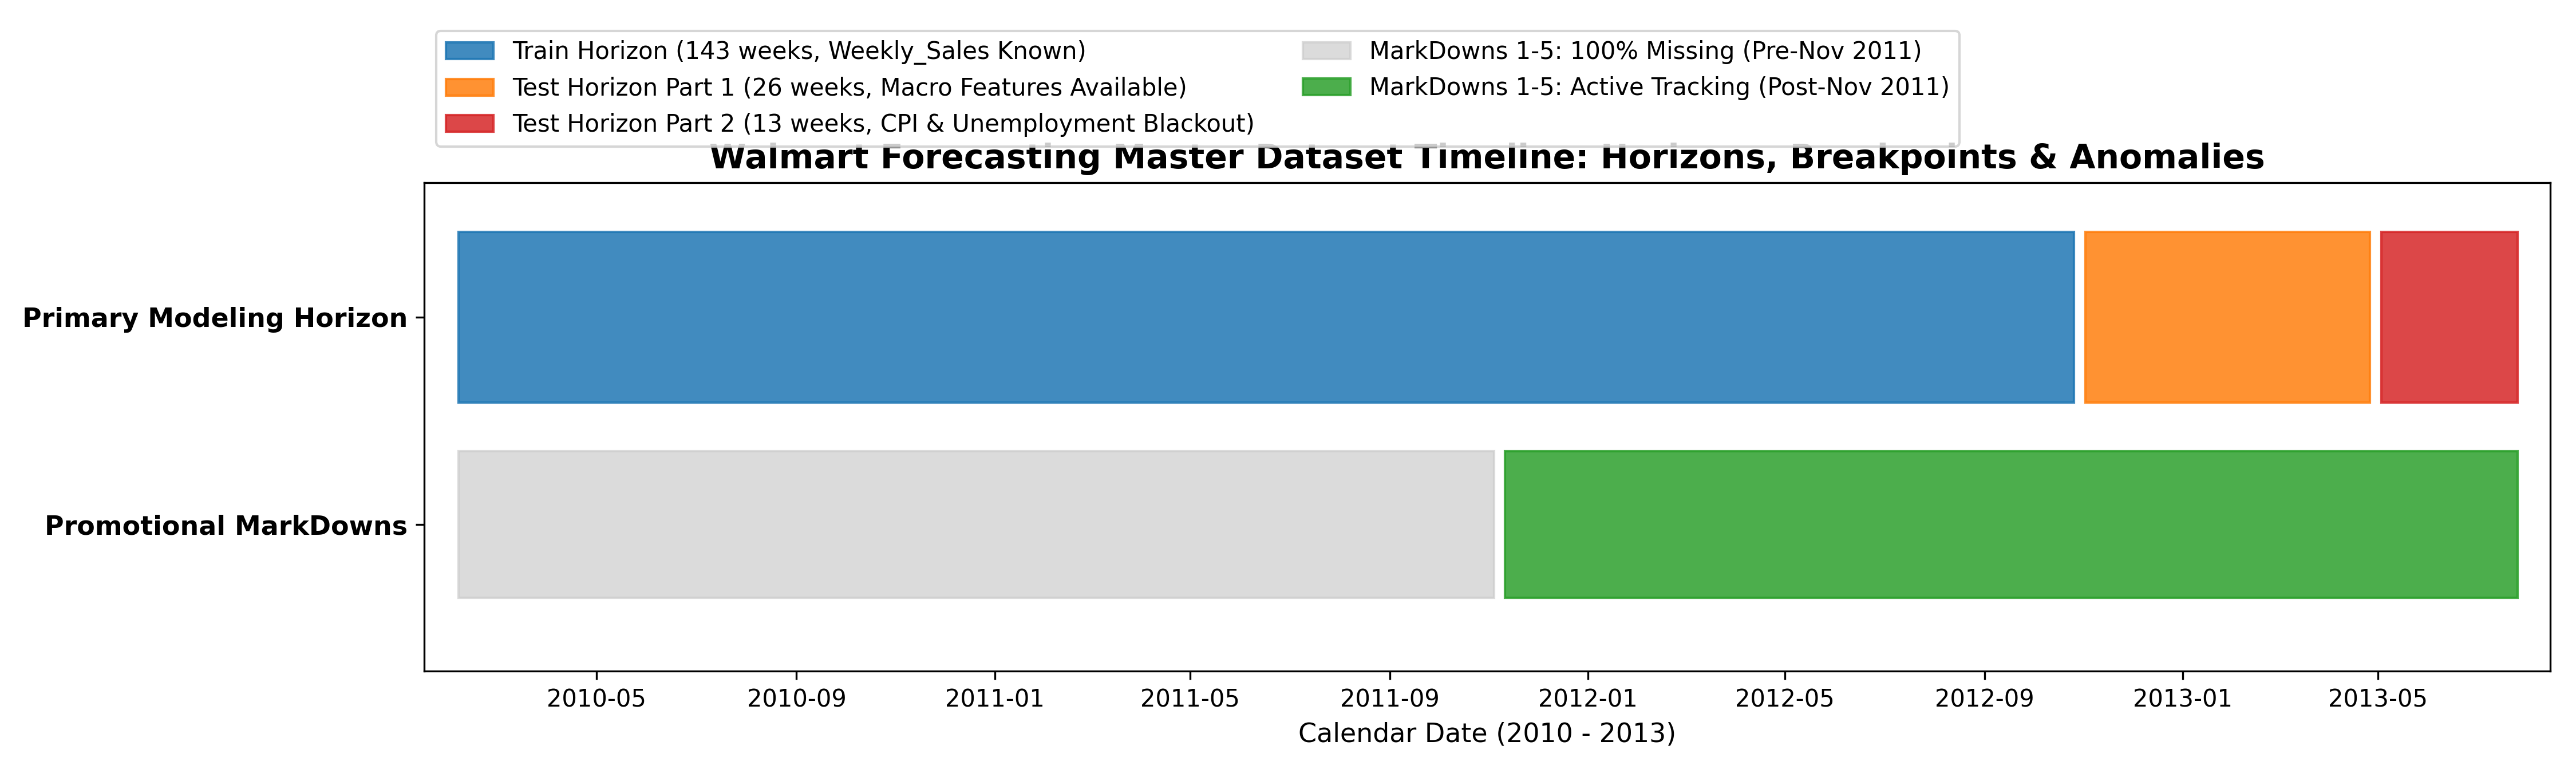

In [8]:
from IPython.display import Image, display
fig_path = os.path.join("..", "outputs", "figures", "fig01_dataset_timeline_overview.png")
if os.path.exists(fig_path):
    display(Image(filename=fig_path))
else:
    print("Timeline figure not found at:", fig_path)
